# GENERATE MODELS USING OBJECT-CENTRIC PROCESS MINING

`discover_ocdfg` is applied to the whole log of each coding scheme and to each cluster, in two views:
the conversation as the object, and the two agents (learner and LLM) as the objects.

* **Input:** `logs_w_cluster/<coding scheme>.csv`
* **Output:** `results/figures/ocdfg_*.png`
* **Check:** the models show the alternation between the activities of the LLM and of the learner


## DEPENDENCIES

In [1]:
from pathlib import Path
import os
import warnings

import pandas as pd
import pm4py

warnings.filterwarnings('ignore', category=UserWarning)

In [2]:
# Dataset to work on: 'data' is the study data, 'data_example' the synthetic example.
DATA = Path('..') / os.environ.get('DATASET_FOLDER', 'data')

IN_FOLDER = 'logs_w_cluster'

CODING_SCHEMES = ['lin_dialogue_acts',
                  'acosta_epistemic_stance',
                  'del_bosque_cma']

OUT_FOLDER = 'results'

# Names given to the clusters in the paper
PROFILE_NAMES = {
    'lin_dialogue_acts': {0: 'Extended-engagement', 1: 'Task-completion', 2: 'Front-loading'},
    'acosta_epistemic_stance': {0: 'Assignment-driven', 1: 'Gap-filling', 2: 'Sense-making'},
    'del_bosque_cma': {0: 'Tutored', 1: 'Passive', 2: 'Collaborative'},
}

THRESHOLD = 0.05  # hide the activities and edges below 5% of the most frequent one

In [3]:
# Relative path
path_logs = DATA / IN_FOLDER

logs = {}

for code in CODING_SCHEMES:
    # Read dataframe
    df = pd.read_csv(path_logs / (code + '.csv'))
    logs[code] = df

## Function

The threshold is relative: the maximum frequency of an activity and of an edge is computed first, and
both are cut at `THRESHOLD` of it.

In [7]:
def save_ocdfg(df, path, view='agents', threshold=THRESHOLD):

    # Take the object type(s) of this view
    if view == 'agents':
        object_columns = ['ocel:type:model', 'ocel:type:user']
    else:
        object_columns = ['ocel:type:conversation']

    dataframe = df[['case_id', 'ocel:activity', 'ocel:timestamp'] + object_columns].copy()
    # Format the timestamp to avoid problems when discovering the models
    dataframe['ocel:timestamp'] = pd.to_datetime(dataframe['ocel:timestamp'])
    for column in object_columns:
        dataframe[column] = dataframe[column].fillna('')

    ocel = pm4py.convert.convert_log_to_ocel(dataframe,
                                             activity_column='ocel:activity',
                                             timestamp_column='ocel:timestamp')

    # Discover the graph
    ocdfg = pm4py.ocel.discover_ocdfg(ocel)

    if threshold != 0:
        act = []
        for k in ocdfg['activities_indep']['events'].keys():
            act.append(len(ocdfg['activities_indep']['events'][k]))
        act_max = max(act)

        edges = []
        for k in ocdfg['edges']['event_couples'].keys():
            for edge in ocdfg['edges']['event_couples'][k]:
                edges.append(len(ocdfg['edges']['event_couples'][k][edge]))

        edge_max = max(edges)

        act_threshold = threshold * act_max
        edge_threshold = threshold * edge_max

    else:
        act_threshold = 0
        edge_threshold = 0

    # Save the graph
    pm4py.vis.save_vis_ocdfg(ocdfg,
                    str(path),
                    annotation='frequency',
                    act_metric='events',
                    edge_metric='event_couples',
                    act_threshold=act_threshold,
                    edge_threshold=edge_threshold,
                    bgcolor='white')
                    #rankdir='LR')

    return path

## One model per coding scheme, and one per cluster

In [8]:
path_models = DATA / OUT_FOLDER / 'figures'
path_models.mkdir(parents=True, exist_ok=True)

for coding_scheme in logs:
    print(coding_scheme, ':')

    df = logs[coding_scheme]

    for view in ('conversation', 'agents'):
        save_ocdfg(df, path_models / f'ocdfg_{coding_scheme}_{view}.png', view=view)

    # For every cluster in every coding_scheme
    for e in sorted(df['cluster'].unique()):
        cluster_df = df[df['cluster'] == e]
        profile = PROFILE_NAMES[coding_scheme][e].lower().replace(' ', '_')
        print('  cluster', e, ':', len(cluster_df['case_id'].unique()), 'conversations')

        save_ocdfg(cluster_df, path_models / f'ocdfg_{coding_scheme}_cluster{e}_{profile}.png',
                   view='agents')

lin_dialogue_acts :
  cluster 0 : 15 conversations
  cluster 1 : 86 conversations
  cluster 2 : 58 conversations
acosta_epistemic_stance :
  cluster 0 : 38 conversations
  cluster 1 : 74 conversations
  cluster 2 : 47 conversations
del_bosque_cma :
  cluster 0 : 58 conversations
  cluster 1 : 44 conversations
  cluster 2 : 57 conversations


## Example: the whole Epistemic Stance log, agents view

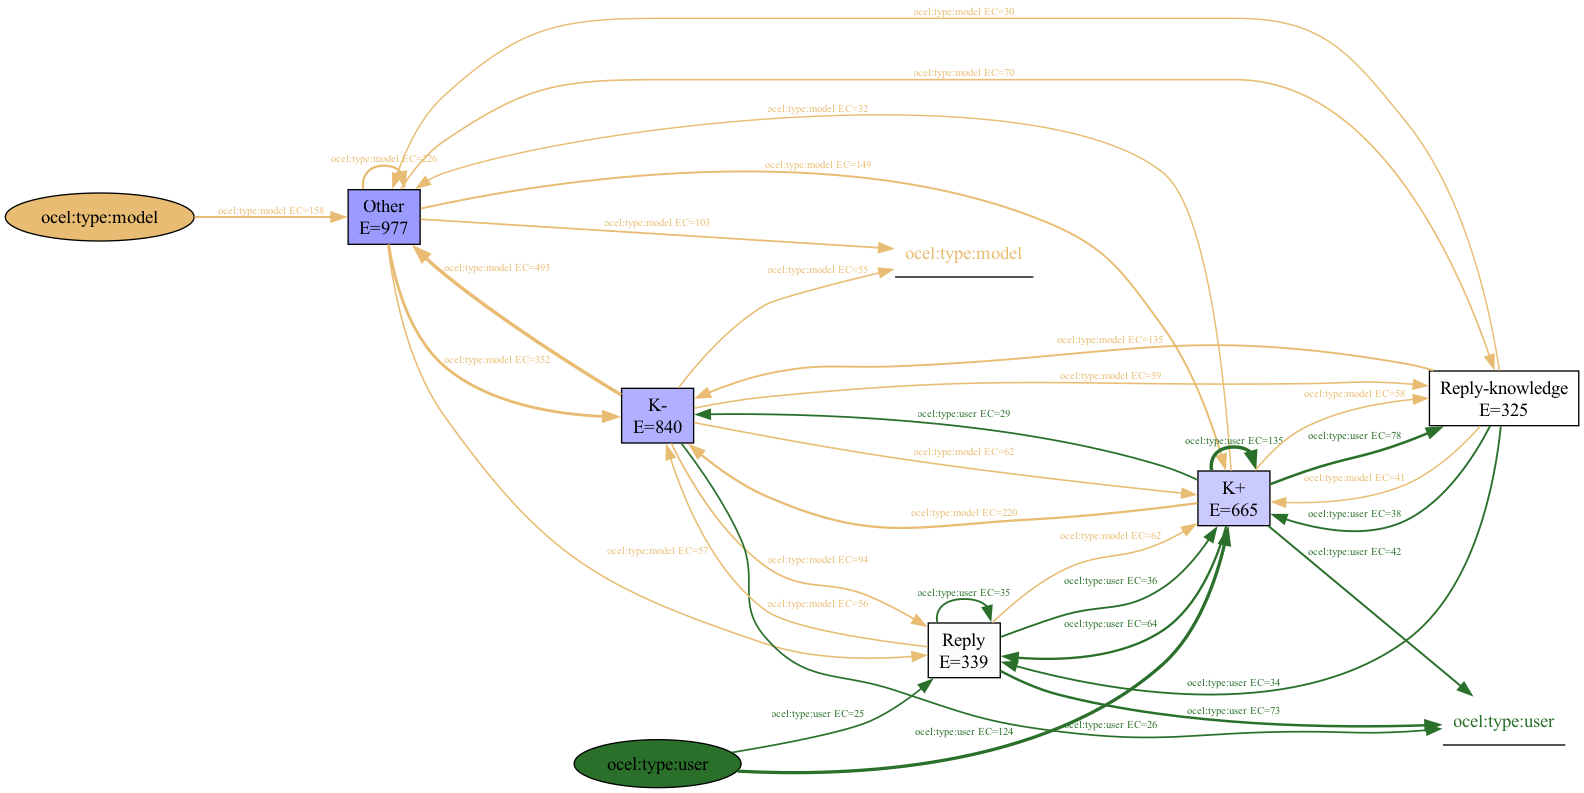

In [9]:
from IPython.display import Image

Image(filename=str(path_models / 'ocdfg_acosta_epistemic_stance_agents.png'))